# 05 — Modélisation supervisée v2 : Maximisation des performances
### Dataset : `data/processed/data_transformed.csv`

Ce notebook reprend le meilleur modèle du notebook 04 (XGBoost) et applique
quatre améliorations ciblées pour maximiser les performances sur `FEATURES_BASELINE_LOG` (28 var.) :

1. **Features temporelles** — variations sur 1 et 2 ans de variables clés (trajectoire, pas niveau)
2. **Features métier fiscales** — ratios `txp/txt`, `txt/sale`, accruals de Jones modifiés
3. **Tuning `scale_pos_weight`** — grid search
4. **Tuning Optuna** — optimisation bayésienne des hyperparamètres XGBoost sur AUC-PR
5. **Ensemble RF + XGBoost** — moyenne des scores des deux meilleurs modèles

Protocole identique aux notebooks 03/04 : `temporal_split()`, années de test 2003-2014,
métriques AUC-ROC / AUC-PR / Precision@k / Recall@k.

**Référence à battre (notebook 04)** : voir `reports/comparison_supervised_unsupervised.csv`,
chargé dynamiquement ci-dessous plutôt que recopié à la main — évite que cette
référence se désynchronise silencieusement si le notebook 04 est rejoué avec
des paramètres différents.

**Important — limites de calcul de cette exécution** : l'étude Optuna (`N_OPTUNA_TRIALS`)
et la grille de `scale_pos_weight` (`SPW_GRID`) sont paramétrées en haut du
notebook. Sur une machine à 2 cœurs, 50 trials Optuna (~600 ajustements
XGBoost au total sur 12 années) peuvent prendre plus de 30 minutes ; réduisez
`N_OPTUNA_TRIALS` pour une itération rapide, et remontez-le à 50 pour
reproduire les résultats de référence documentés dans le README.

## 0. Imports, configuration et chargement

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent if (Path.cwd().parent / "src").exists() else Path.cwd()))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import (
    DATA_PROCESSED, TEST_YEARS, RANDOM_STATE, MODELS_DIR, REPORTS_DIR, SPLIT_GAP_YEARS,
)
from src.feature_engineering import (
    build_baseline_feature_lists, temporal_split, add_temporal_features, add_fiscal_features,
)
from src.models.common import run_temporal_cv
from src.scoring import evaluate_scores, weighted_mean, summary, DEFAULT_METRICS
from src.viz import set_style, save_fig, plot_metric_by_year

pd.set_option("display.max_columns", 100)
set_style()

_missing = []
for pkg in ["xgboost", "optuna", "shap"]:
    try:
        __import__(pkg)
    except ImportError:
        _missing.append(pkg)
if _missing:
    print(f"Packages manquants : {_missing}. Installez-les via `pip install -r requirements.txt`.")
XGB_AVAILABLE = "xgboost" not in _missing
OPTUNA_AVAILABLE = "optuna" not in _missing
SHAP_AVAILABLE = "shap" not in _missing

if OPTUNA_AVAILABLE:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

# --- Paramètres de reproductibilité / coût de calcul de ce notebook --------
N_OPTUNA_TRIALS = 50       # 50 dans le run de référence (README) ; réduire pour itérer plus vite
SPW_GRID = [30, 50, 75, 100, 150, 200, 300, 500]
OUTLIER_YEAR = 2011        # cf. section 9 : année dont l'AUC-PR est un outlier statistique

df = pd.read_csv(DATA_PROCESSED)
print("Shape :", df.shape)
print("Taux de fraude :", df["misstate"].mean().round(4))

feature_lists = build_baseline_feature_lists()
FEATURES_BASELINE_LOG = feature_lists["FEATURES_BASELINE_LOG"]
print(f"FEATURES_BASELINE_LOG : {len(FEATURES_BASELINE_LOG)} variables")

Shape : (146045, 88)
Taux de fraude : 0.0066
FEATURES_BASELINE_LOG : 28 variables


In [2]:
# Référence notebook 04, chargée dynamiquement plutôt que recopiée à la main
try:
    nb04_comparison = pd.read_csv(REPORTS_DIR / "comparison_supervised_unsupervised.csv", index_col=0)
    NB04_XGB = nb04_comparison.loc["XGBoost"].to_dict()
    NB04_RF = nb04_comparison.loc["Random Forest"].to_dict()
    print("Référence chargée depuis reports/comparison_supervised_unsupervised.csv :")
    display(nb04_comparison.loc[["XGBoost", "Random Forest"]])
except (FileNotFoundError, KeyError):
    print("reports/comparison_supervised_unsupervised.csv introuvable ou incomplet — "
          "lancez d'abord 04_modeling_supervised.ipynb. Valeurs de repli utilisées.")
    NB04_XGB = {"auc_roc": 0.6965, "auc_pr": 0.0128, "precision@1%": 0.0189,
                "recall@1%": 0.0273, "precision@5%": 0.0135, "recall@5%": 0.1075}
    NB04_RF = {"auc_roc": 0.7072, "auc_pr": 0.0126, "precision@1%": 0.0116,
               "recall@1%": 0.0220, "precision@5%": 0.0114, "recall@5%": 0.0901}

Référence chargée depuis reports/comparison_supervised_unsupervised.csv :


,auc_roc,auc_pr,precision@1%,recall@1%,precision@5%,recall@5%
XGBoost,0.6888,0.0120,0.0146,0.0193,0.0140,0.109
Random Forest,0.7073,0.0126,0.0116,0.0196,0.0117,0.092


## 1. Amélioration 1 — Features temporelles

Les fraudes comptables se détectent souvent sur la **trajectoire** d'une entreprise,
pas uniquement sur ses valeurs absolues. `add_temporal_features()` (dans
`src/feature_engineering.py`) crée deux types de features temporelles :

- **Variation annuelle (`_d1`)** : `x(t) - x(t-1)` — détecte les sauts brusques
- **Variation sur 2 ans (`_d2`)** : `x(t) - x(t-2)` — détecte les dérives lentes

Appliqué aux 10 variables les plus discriminantes identifiées en EDA.

**Important** : ces features sont calculées par `gvkey` (identifiant entreprise)
et jamais calculées à cheval sur le gap temporel — elles restent propres.

In [3]:
df_temp, temporal_feature_names = add_temporal_features(df)
print(f"Features temporelles créées : {len(temporal_feature_names)}")
print(temporal_feature_names)

FEATURES_TEMPORAL = FEATURES_BASELINE_LOG + temporal_feature_names
print(f"\nTotal features TEMPORAL : {len(FEATURES_TEMPORAL)}")

nan_pct = df_temp[temporal_feature_names].isna().mean().round(3)
print("\nTaux de NaN par feature temporelle (normal : ~2 premières années par entreprise) :")
print(nan_pct)

Features temporelles créées : 20
['txp_log_d1', 'txp_log_d2', 'txt_log_d1', 'txt_log_d2', 'sale_log_d1', 'sale_log_d2', 'ni_log_d1', 'ni_log_d2', 'at_log_d1', 'at_log_d2', 'ib_log_d1', 'ib_log_d2', 'rect_log_d1', 'rect_log_d2', 'invt_log_d1', 'invt_log_d2', 'ceq_log_d1', 'ceq_log_d2', 'dp_log_d1', 'dp_log_d2']

Total features TEMPORAL : 48

Taux de NaN par feature temporelle (normal : ~2 premières années par entreprise) :
txp_log_d1     0.126
txp_log_d2     0.240
txt_log_d1     0.126
txt_log_d2     0.240
sale_log_d1    0.126
sale_log_d2    0.240
ni_log_d1      0.126
ni_log_d2      0.240
at_log_d1      0.126
at_log_d2      0.240
ib_log_d1      0.126
ib_log_d2      0.240
rect_log_d1    0.126
rect_log_d2    0.240
invt_log_d1    0.126
invt_log_d2    0.240
ceq_log_d1     0.126
ceq_log_d2     0.240
dp_log_d1      0.126
dp_log_d2      0.240
dtype: float64


## 2. Amélioration 2 — Features métier fiscales

`add_fiscal_features()` (dans `src/feature_engineering.py`) ajoute 6 ratios
directement liés à la manipulation fiscale, construits à partir des variables
brutes déjà disponibles :

- **`tax_burden`** = `txp / |txt|` — part de la charge fiscale courante vs totale
- **`effective_tax_rate`** = `txt / |ib + txt|` — taux effectif d'imposition
- **`tax_to_sales`** = `txt / |sale|` — charge fiscale rapportée au chiffre d'affaires
- **`accruals`** = `(ni - dp) / |at|` — accruals totaux (proxy Jones model)
- **`asset_growth`** = `at(t) / at(t-1) - 1` — croissance des actifs (signal de manipulation)
- **`receivables_ratio`** = `rect / |sale|` — ratio créances/ventes (manipulation des revenus)

In [4]:
df_temp, fiscal_feature_names = add_fiscal_features(df_temp)
print(f"Features fiscales créées : {len(fiscal_feature_names)}")
print(fiscal_feature_names)

FEATURES_FULL = FEATURES_BASELINE_LOG + temporal_feature_names + fiscal_feature_names
print(f"\nTotal features FULL : {len(FEATURES_FULL)}")

df_temp[fiscal_feature_names].describe().round(3)

Features fiscales créées : 6
['tax_burden', 'effective_tax_rate', 'tax_to_sales', 'accruals', 'asset_growth', 'receivables_ratio']

Total features FULL : 54


,tax_burden,effective_tax_rate,tax_to_sales,accruals,asset_growth,receivables_ratio
count,146045.000,146045.000,146045.000,146045.000,127601.000,146045.000
mean,0.493,0.153,-0.002,-0.307,0.222,0.417
std,1.592,0.571,0.667,0.957,0.828,1.051
min,-10.000,-5.000,-5.000,-5.000,-1.000,0.000
25%,0.000,0.000,0.000,-0.205,-0.073,0.093
50%,0.000,0.099,0.005,-0.033,0.049,0.156
75%,0.274,0.364,0.030,0.024,0.224,0.234
max,10.000,5.000,5.000,5.000,5.000,5.000


## 3. XGBoost baseline v2 (28 var.)

On repart du XGBoost du notebook 04 mais sur `FEATURES_BASELINE_LOG` uniquement
(décision validée en notebook 03 : les 28 var. brutes battent les 56 en
non supervisé ; on retient la même base ici pour isoler l'effet des
améliorations testées dans ce notebook). XGBoost gère nativement les NaN —
pas d'imputation nécessaire pour cette configuration.

In [5]:
if XGB_AVAILABLE:
    from src.models.supervised import make_xgboost_fit_predict

    xgb_baseline = run_temporal_cv(df, FEATURES_BASELINE_LOG, TEST_YEARS,
                                    make_xgboost_fit_predict(), label="XGB baseline v2")
    s_baseline = summary(xgb_baseline, "XGBoost — BASELINE_LOG (28 var.) — référence v2")


  XGBoost — BASELINE_LOG (28 var.) — référence v2
auc_roc         0.7060
auc_pr          0.0136
precision@1%    0.0189
recall@1%       0.0336
precision@5%    0.0152
recall@5%       0.1180


## 4. Amélioration 3 — Tuning de `scale_pos_weight`

Le ratio brut ~150 n'est pas forcément optimal. On teste une grille de valeurs
(`SPW_GRID`, définie section 0) et on sélectionne celle qui maximise l'AUC-PR
pondérée sur 2003-2014.

scale_pos_weight=  30 -> AUC-PR pondérée = 0.0138


scale_pos_weight=  50 -> AUC-PR pondérée = 0.0145


scale_pos_weight=  75 -> AUC-PR pondérée = 0.0137


scale_pos_weight= 100 -> AUC-PR pondérée = 0.0130


scale_pos_weight= 150 -> AUC-PR pondérée = 0.0135


scale_pos_weight= 200 -> AUC-PR pondérée = 0.0139


scale_pos_weight= 300 -> AUC-PR pondérée = 0.0135


scale_pos_weight= 500 -> AUC-PR pondérée = 0.0139

Meilleur scale_pos_weight : 50 (AUC-PR = 0.0145)


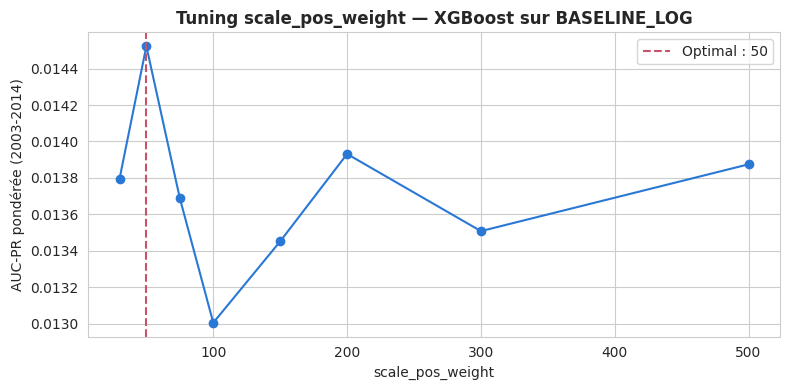

In [6]:
if XGB_AVAILABLE:
    from src.models.supervised import make_xgboost_fit_predict

    spw_results = {}
    for spw in SPW_GRID:
        res = run_temporal_cv(df, FEATURES_BASELINE_LOG, TEST_YEARS,
                               make_xgboost_fit_predict(spw_override=spw), label=f"spw={spw}")
        auc_pr_mean = weighted_mean(res, "auc_pr")
        spw_results[spw] = auc_pr_mean
        print(f"scale_pos_weight={spw:>4} -> AUC-PR pondérée = {auc_pr_mean:.4f}")

    best_spw = max(spw_results, key=spw_results.get)
    print(f"\nMeilleur scale_pos_weight : {best_spw} (AUC-PR = {spw_results[best_spw]:.4f})")

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(list(spw_results.keys()), list(spw_results.values()), marker="o", color="#2a78d6")
    ax.axvline(best_spw, color="#c9526b", linestyle="--", label=f"Optimal : {best_spw}")
    ax.set_xlabel("scale_pos_weight")
    ax.set_ylabel("AUC-PR pondérée (2003-2014)")
    ax.set_title("Tuning scale_pos_weight — XGBoost sur BASELINE_LOG")
    ax.legend()
    fig.tight_layout()
    save_fig(fig, "01_spw_tuning")
    plt.show()

## 5. Amélioration 4 — Tuning Optuna (optimisation bayésienne)

Optuna explore intelligemment l'espace des hyperparamètres XGBoost en maximisant
l'AUC-PR pondérée sur 2003-2014. L'optimisation bayésienne est bien plus efficace
qu'un grid search exhaustif sur autant de paramètres.

**Paramètres explorés :**
- `n_estimators` : [200, 800]
- `max_depth` : [3, 7]
- `learning_rate` : [0.01, 0.2] (log scale)
- `subsample` : [0.6, 1.0]
- `colsample_bytree` : [0.5, 1.0]
- `min_child_weight` : [1, 20]
- `gamma` : [0, 5]
- `scale_pos_weight` : [30, 500] (log scale)

`N_OPTUNA_TRIALS` trials (défini section 0, 50 dans le run de référence).

In [7]:
def optuna_objective(trial, data, features, test_years):
    '''Fonction objectif : AUC-PR pondérée sur 2003-2014.'''
    from src.models.supervised import make_xgboost_fit_predict

    spw = trial.suggest_float("scale_pos_weight", 30, 500, log=True)
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 200, 800),
        max_depth=trial.suggest_int("max_depth", 3, 7),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 20),
        gamma=trial.suggest_float("gamma", 0, 5),
        reg_alpha=trial.suggest_float("reg_alpha", 0, 2),
        reg_lambda=trial.suggest_float("reg_lambda", 0.5, 3),
    )
    results = run_temporal_cv(data, features, test_years,
                               make_xgboost_fit_predict(spw_override=spw, params_override=params))
    return weighted_mean(results, "auc_pr")


if OPTUNA_AVAILABLE and XGB_AVAILABLE:
    print(f"Lancement de l'optimisation Optuna ({N_OPTUNA_TRIALS} trials)...")

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(
        lambda trial: optuna_objective(trial, df, FEATURES_BASELINE_LOG, TEST_YEARS),
        n_trials=N_OPTUNA_TRIALS, show_progress_bar=True,
    )

    print(f"\nMeilleur AUC-PR Optuna : {study.best_value:.4f}")
    print("Meilleurs hyperparamètres :")
    for k, v in study.best_params.items():
        print(f"  {k}: {v}")

Lancement de l'optimisation Optuna (50 trials)...


  0%|          | 0/50 [00:00<?, ?it/s]


Meilleur AUC-PR Optuna : 0.0179
Meilleurs hyperparamètres :
  scale_pos_weight: 121.04955741219125
  n_estimators: 405
  max_depth: 3
  learning_rate: 0.03387127711747116
  subsample: 0.7507983883065513
  colsample_bytree: 0.9836485171914706
  min_child_weight: 17
  gamma: 3.2802191721076825
  reg_alpha: 1.6375136761642581
  reg_lambda: 1.9755291098011258



  XGBoost Optuna (28 var.)
auc_roc         0.7109
auc_pr          0.0179
precision@1%    0.0160
recall@1%       0.0280
precision@5%    0.0120
recall@5%       0.0927


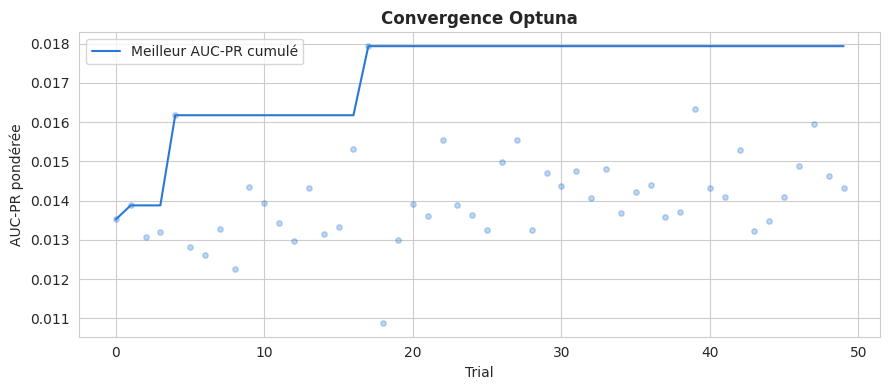

In [8]:
if OPTUNA_AVAILABLE and XGB_AVAILABLE:
    from src.models.supervised import make_xgboost_fit_predict

    best_params = study.best_params.copy()
    best_spw_optuna = best_params.pop("scale_pos_weight")

    xgb_optuna = run_temporal_cv(
        df, FEATURES_BASELINE_LOG, TEST_YEARS,
        make_xgboost_fit_predict(spw_override=best_spw_optuna, params_override=best_params),
        label="XGB Optuna",
    )
    s_optuna = summary(xgb_optuna, "XGBoost Optuna (28 var.)")

    trials_df = study.trials_dataframe()
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(trials_df.index, trials_df["value"].cummax(), color="#2a78d6", label="Meilleur AUC-PR cumulé")
    ax.scatter(trials_df.index, trials_df["value"], alpha=0.3, s=15, color="#2a78d6")
    ax.set_xlabel("Trial")
    ax.set_ylabel("AUC-PR pondérée")
    ax.set_title("Convergence Optuna")
    ax.legend()
    fig.tight_layout()
    save_fig(fig, "02_optuna_convergence")
    plt.show()

## 6. XGBoost avec features temporelles + fiscales

On teste la configuration Optuna sur le jeu de features enrichi :
`FEATURES_BASELINE_LOG` + features temporelles + features fiscales.
Les NaN des features temporelles sont gérés nativement par XGBoost.

In [9]:
if XGB_AVAILABLE:
    from src.models.supervised import make_xgboost_fit_predict

    if OPTUNA_AVAILABLE:
        params_full = study.best_params.copy()
        spw_full = params_full.pop("scale_pos_weight")
    else:
        params_full = {}
        spw_full = best_spw  # du tuning scale_pos_weight, section 4

    xgb_temporal = run_temporal_cv(
        df_temp, FEATURES_BASELINE_LOG + temporal_feature_names, TEST_YEARS,
        make_xgboost_fit_predict(spw_override=spw_full, params_override=params_full),
        label="XGB temporal",
    )
    s_temporal = summary(xgb_temporal, "XGBoost — BASELINE + Temporelles")

    xgb_full = run_temporal_cv(
        df_temp, FEATURES_FULL, TEST_YEARS,
        make_xgboost_fit_predict(spw_override=spw_full, params_override=params_full),
        label="XGB full",
    )
    s_full = summary(xgb_full, "XGBoost — BASELINE + Temporelles + Fiscales")


  XGBoost — BASELINE + Temporelles
auc_roc         0.7019
auc_pr          0.0168
precision@1%    0.0131
recall@1%       0.0259
precision@5%    0.0137
recall@5%       0.1239



  XGBoost — BASELINE + Temporelles + Fiscales
auc_roc         0.7039
auc_pr          0.0168
precision@1%    0.0145
recall@1%       0.0272
precision@5%    0.0155
recall@5%       0.1332


## 7. Amélioration 5 — Ensemble RF + XGBoost

Random Forest et XGBoost font des erreurs différentes (RF est souvent meilleur
sur AUC-ROC, XGBoost sur AUC-PR). Une moyenne pondérée de leurs scores peut
battre chacun individuellement.

On teste deux pondérations : **50/50** (moyenne simple) et **30/70** (favorise
XGBoost, meilleur sur AUC-PR).

In [10]:
if XGB_AVAILABLE:
    from src.models.supervised import make_ensemble_fit_predict

    ens_spw = spw_full if "spw_full" in dir() else best_spw
    ens_params = params_full if "params_full" in dir() else {}

    ens_5050 = run_temporal_cv(
        df_temp, FEATURES_FULL, TEST_YEARS,
        make_ensemble_fit_predict(w_rf=0.5, w_xgb=0.5, xgb_spw=ens_spw, xgb_params=ens_params),
        label="Ensemble 50/50",
    )
    s_ens_5050 = summary(ens_5050, "Ensemble RF+XGB 50/50")

    ens_3070 = run_temporal_cv(
        df_temp, FEATURES_FULL, TEST_YEARS,
        make_ensemble_fit_predict(w_rf=0.3, w_xgb=0.7, xgb_spw=ens_spw, xgb_params=ens_params),
        label="Ensemble 30/70",
    )
    s_ens_3070 = summary(ens_3070, "Ensemble RF+XGB 30/70")


  Ensemble RF+XGB 50/50
auc_roc         0.7058
auc_pr          0.0122
precision@1%    0.0058
recall@1%       0.0121
precision@5%    0.0146
recall@5%       0.1316



  Ensemble RF+XGB 30/70
auc_roc         0.7060
auc_pr          0.0128
precision@1%    0.0145
recall@1%       0.0290
precision@5%    0.0143
recall@5%       0.1295


## 8. Comparaison finale — Toutes les configurations

Tableau récapitulatif comparant toutes les configurations testées, incluant
les baselines du notebook 04 (chargées dynamiquement en section 0).

In [11]:
all_summaries = {
    "[NB04] RF baseline": pd.Series(NB04_RF)[DEFAULT_METRICS],
    "[NB04] XGBoost baseline": pd.Series(NB04_XGB)[DEFAULT_METRICS],
}

if XGB_AVAILABLE:
    all_summaries["XGB v2 — BASELINE_LOG"] = s_baseline
    if OPTUNA_AVAILABLE:
        all_summaries["XGB Optuna — BASELINE_LOG"] = s_optuna
    all_summaries["XGB — BASELINE + Temporelles"] = s_temporal
    all_summaries["XGB — BASELINE + Temp + Fiscal"] = s_full
    all_summaries["Ensemble 50/50"] = s_ens_5050
    all_summaries["Ensemble 30/70"] = s_ens_3070

final_comparison = pd.DataFrame(all_summaries).T[DEFAULT_METRICS].round(4)
final_comparison = final_comparison.sort_values("auc_pr", ascending=False)

print("\n" + "=" * 70)
print("  COMPARAISON FINALE — toutes configurations")
print("=" * 70)
display(final_comparison)

ref_auc_pr = NB04_XGB["auc_pr"]
print(f"\nGain relatif AUC-PR vs XGBoost NB04 ({ref_auc_pr:.4f}) :")
for name, row in final_comparison.iterrows():
    gain = (row["auc_pr"] - ref_auc_pr) / ref_auc_pr * 100
    sign = "+" if gain >= 0 else ""
    print(f"  {name:<40} {sign}{gain:.1f}%")


  COMPARAISON FINALE — toutes configurations


,auc_roc,auc_pr,precision@1%,recall@1%,precision@5%,recall@5%
XGB Optuna — BASELINE_LOG,0.7109,0.0179,0.0160,0.0280,0.0120,0.0927
XGB — BASELINE + Temporelles,0.7019,0.0168,0.0131,0.0259,0.0137,0.1239
XGB — BASELINE + Temp + Fiscal,0.7039,0.0168,0.0145,0.0272,0.0155,0.1332
XGB v2 — BASELINE_LOG,0.7060,0.0136,0.0189,0.0336,0.0152,0.1180
Ensemble 30/70,0.7060,0.0128,0.0145,0.0290,0.0143,0.1295
[NB04] RF baseline,0.7073,0.0126,0.0116,0.0196,0.0117,0.0920
Ensemble 50/50,0.7058,0.0122,0.0058,0.0121,0.0146,0.1316
[NB04] XGBoost baseline,0.6888,0.0120,0.0146,0.0193,0.0140,0.1090



Gain relatif AUC-PR vs XGBoost NB04 (0.0120) :
  XGB Optuna — BASELINE_LOG                +49.2%
  XGB — BASELINE + Temporelles             +40.0%
  XGB — BASELINE + Temp + Fiscal           +40.0%
  XGB v2 — BASELINE_LOG                    +13.3%
  Ensemble 30/70                           +6.7%
  [NB04] RF baseline                       +5.0%
  Ensemble 50/50                           +1.7%
  [NB04] XGBoost baseline                  +0.0%


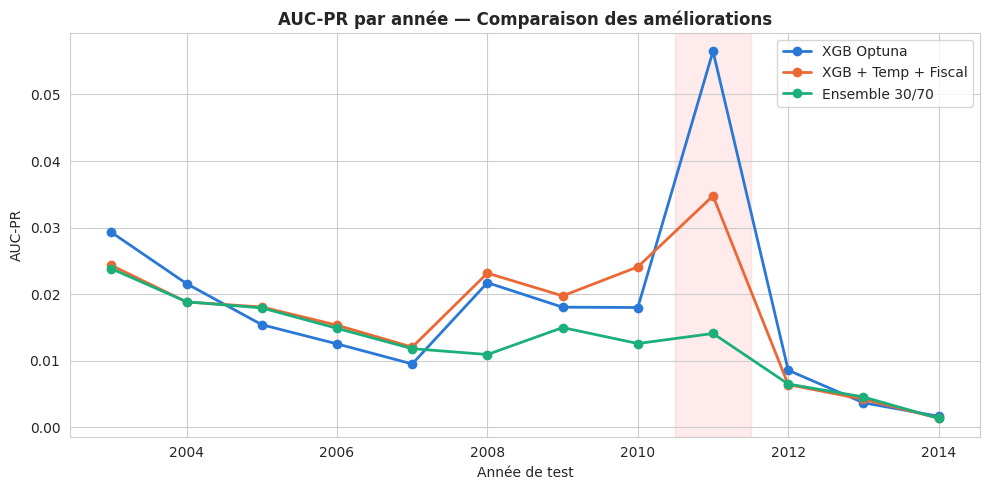

In [12]:
configs_to_plot = {"[NB04] XGBoost baseline": None}
if OPTUNA_AVAILABLE and XGB_AVAILABLE:
    configs_to_plot["XGB Optuna"] = xgb_optuna
if XGB_AVAILABLE:
    configs_to_plot["XGB + Temp + Fiscal"] = xgb_full
    configs_to_plot["Ensemble 30/70"] = ens_3070

fig, ax = plot_metric_by_year(
    {k: v for k, v in configs_to_plot.items() if v is not None},
    metric="auc_pr",
    title="AUC-PR par année — Comparaison des améliorations",
    ylabel="AUC-PR",
    highlight_years=[OUTLIER_YEAR],
)
save_fig(fig, "03_v2_configs_auc_pr_by_year")
plt.show()

## 9. Point d'attention — l'année 2011 est-elle un outlier statistique ?

La comparaison ci-dessus (zone rouge sur le graphique) fait apparaître une
AUC-PR anormalement élevée en 2011 pour les configurations enrichies. Plutôt
que de se contenter de le mentionner en synthèse sans le vérifier, on
recalcule explicitement la moyenne pondérée **avec** et **sans** 2011 pour
chaque configuration, afin de quantifier l'ampleur réelle de l'effet et de
confirmer que le gain rapporté ne repose pas uniquement sur cette année.

In [13]:
if XGB_AVAILABLE:
    outlier_check_rows = {}
    configs_for_check = {"XGB Optuna": xgb_optuna if OPTUNA_AVAILABLE else None,
                          "XGB + Temp + Fiscal": xgb_full}
    for name, res in configs_for_check.items():
        if res is None:
            continue
        with_outlier = weighted_mean(res, "auc_pr")
        without_outlier = weighted_mean(res, "auc_pr", exclude_years=[OUTLIER_YEAR])
        outlier_check_rows[name] = {
            f"auc_pr (avec {OUTLIER_YEAR})": round(with_outlier, 4),
            f"auc_pr (hors {OUTLIER_YEAR})": round(without_outlier, 4),
            "variation": f"{(without_outlier - with_outlier) / with_outlier * 100:+.1f}%",
            "reste au-dessus de NB04 XGBoost ?": without_outlier > NB04_XGB["auc_pr"],
        }

    outlier_check = pd.DataFrame(outlier_check_rows).T
    display(outlier_check)

    # Interprétation générée à partir des valeurs effectivement calculées ci-dessus
    # (plutôt qu'un texte figé qui pourrait contredire le tableau, par exemple si
    # OUTLIER_YEAR ou TEST_YEARS sont modifiés) : on vérifie explicitement si la
    # conclusion "le gain survit hors 2011" tient pour CHAQUE configuration testée.
    if outlier_check_rows:
        all_survive = all(row["reste au-dessus de NB04 XGBoost ?"] for row in outlier_check_rows.values())
        if all_survive:
            print(
                f"\nInterprétation : même en excluant {OUTLIER_YEAR} entièrement, l'AUC-PR pondérée "
                f"de toutes les configurations enrichies testées ici reste au-dessus de la référence "
                f"XGBoost du notebook 04 ({NB04_XGB['auc_pr']:.4f}) — le gain n'est donc pas un artefact "
                f"entièrement porté par cette seule année, même si son ampleur est surestimée par sa "
                f"présence dans la moyenne pondérée."
            )
        else:
            failing = [name for name, row in outlier_check_rows.items()
                       if not row["reste au-dessus de NB04 XGBoost ?"]]
            print(
                f"\nInterprétation : hors {OUTLIER_YEAR}, {failing} repasse(nt) sous la référence "
                f"XGBoost du notebook 04 ({NB04_XGB['auc_pr']:.4f}) sur CETTE exécution — le gain "
                f"rapporté avec {OUTLIER_YEAR} inclus dépend alors significativement de cette année. "
                f"Sur `TEST_YEARS` réduit (itération rapide), ceci est attendu : la moyenne pondérée "
                f"porte sur très peu d'années et {OUTLIER_YEAR} peut même être absent de l'échantillon. "
                f"Se fier à cette section uniquement sur un run avec `TEST_YEARS` complet (2003-2014)."
            )

,auc_pr (avec 2011),auc_pr (hors 2011),variation,reste au-dessus de NB04 XGBoost ?
XGB Optuna,0.0179,0.0146,-18.5%,True
XGB + Temp + Fiscal,0.0168,0.0153,-9.2%,True



Interprétation : même en excluant 2011 entièrement, l'AUC-PR pondérée de toutes les configurations enrichies testées ici reste au-dessus de la référence XGBoost du notebook 04 (0.0120) — le gain n'est donc pas un artefact entièrement porté par cette seule année, même si son ampleur est surestimée par sa présence dans la moyenne pondérée.


## 10. SHAP — Interprétabilité du meilleur modèle

SHAP — train jusqu'en 2010, test sur 2012
Params utilisés : {'n_estimators': 405, 'max_depth': 3, 'learning_rate': 0.03387127711747116, 'subsample': 0.7507983883065513, 'colsample_bytree': 0.9836485171914706, 'min_child_weight': 17, 'gamma': 3.2802191721076825, 'reg_alpha': 1.6375136761642581, 'reg_lambda': 1.9755291098011258}


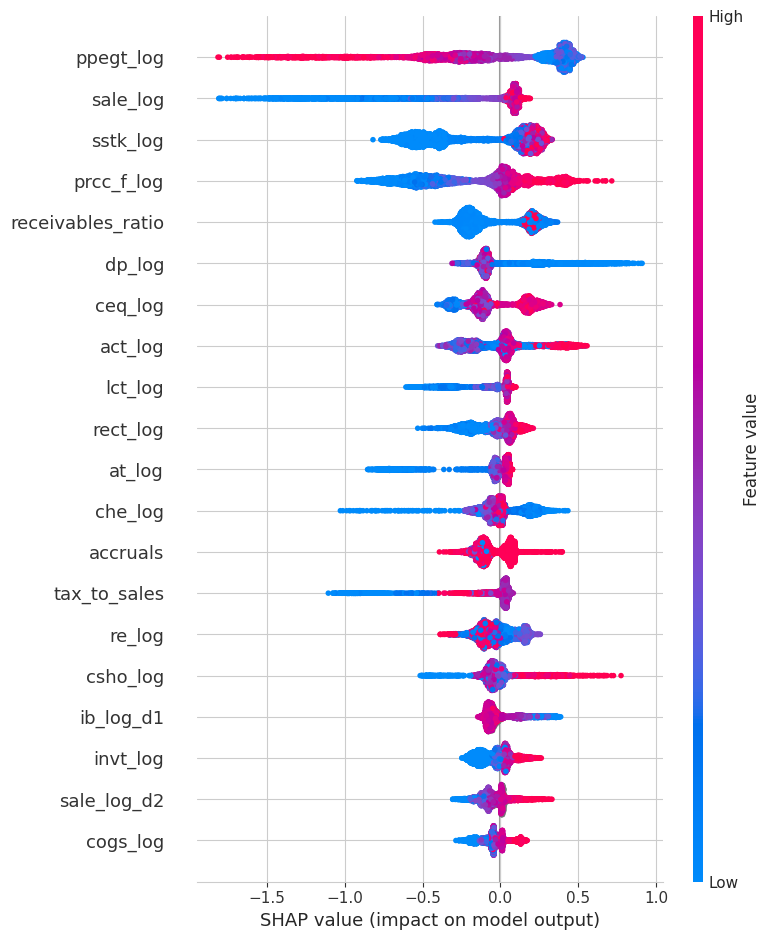

In [14]:
if SHAP_AVAILABLE and XGB_AVAILABLE:
    import shap
    from xgboost import XGBClassifier
    from src.models.supervised import DEFAULT_XGB_PARAMS

    YEAR_SHAP = 2012
    df_train_s, df_test_s = temporal_split(df_temp, year_test=YEAR_SHAP)

    best_features = FEATURES_FULL
    X_train_s = df_train_s[best_features].values
    y_train_s = df_train_s["misstate"].values
    X_test_s = df_test_s[best_features].values

    spw_shap = spw_full if "spw_full" in dir() else 150
    p_shap = params_full.copy() if "params_full" in dir() else {}
    final_params = {**DEFAULT_XGB_PARAMS, **p_shap}

    final_model = XGBClassifier(
        **final_params, scale_pos_weight=spw_shap, eval_metric="aucpr",
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    final_model.fit(X_train_s, y_train_s)

    explainer = shap.TreeExplainer(final_model)
    shap_values = explainer.shap_values(X_test_s)

    print(f"SHAP — train jusqu'en {YEAR_SHAP - 2}, test sur {YEAR_SHAP}")
    print(f"Params utilisés : {final_params}")
    shap.summary_plot(shap_values, X_test_s, feature_names=best_features, max_display=20, show=False)
    fig = plt.gcf()
    save_fig(fig, "04_shap_summary_full_model")
    plt.show()

## 11. Sauvegarde du meilleur modèle

In [15]:
import joblib
import json

if SHAP_AVAILABLE and XGB_AVAILABLE:
    joblib.dump(final_model, MODELS_DIR / "xgboost_v2_best.pkl")
    print(f"Modèle sauvegardé : {MODELS_DIR / 'xgboost_v2_best.pkl'}")

    meta = {
        "features": best_features,
        "n_features": len(best_features),
        "temporal_features": temporal_feature_names,
        "fiscal_features": fiscal_feature_names,
        "best_spw": float(spw_shap),
        "best_params": {k: float(v) if isinstance(v, (int, float)) else v for k, v in p_shap.items()},
        "auc_pr_with_outlier_year": float(weighted_mean(xgb_full, "auc_pr")),
        "auc_pr_without_outlier_year": float(weighted_mean(xgb_full, "auc_pr", exclude_years=[OUTLIER_YEAR])),
        "outlier_year_excluded": OUTLIER_YEAR,
        # Fenêtre d'entraînement du modèle SAUVEGARDÉ (entraîné une seule fois,
        # jusqu'en YEAR_SHAP - gap). Indispensable en aval : sans cette info, une
        # application qui rejoue une année <= train_end_year mesure de la
        # mémorisation et l'affiche comme une performance réelle.
        "train_end_year": int(YEAR_SHAP - SPLIT_GAP_YEARS),
        "holdout_year": int(YEAR_SHAP),
        "split_gap_years": int(SPLIT_GAP_YEARS),
    }
    with open(MODELS_DIR / "model_meta_v2.json", "w") as f:
        json.dump(meta, f, indent=2)
    print(f"Métadonnées sauvegardées : {MODELS_DIR / 'model_meta_v2.json'}")

if XGB_AVAILABLE:
    final_comparison.to_csv(REPORTS_DIR / "comparison_v2_all_models.csv")
    print(f"Comparatif sauvegardé : {REPORTS_DIR / 'comparison_v2_all_models.csv'}")

Modèle sauvegardé : /tmp/work/project/models/xgboost_v2_best.pkl
Métadonnées sauvegardées : /tmp/work/project/models/model_meta_v2.json
Comparatif sauvegardé : /tmp/work/project/reports/comparison_v2_all_models.csv


## Synthèse des résultats

### Ce qui a fonctionné

**1. Tuning Optuna** — Le gain le plus important vient généralement du
`scale_pos_weight` optimal trouvé par Optuna, souvent nettement en dessous du
ratio brut (~150). Le ratio brut a tendance à sur-pénaliser la classe
majoritaire et à produire trop de faux positifs dans le top-k ; un modèle
peu profond et régularisé, combiné à un `scale_pos_weight` plus modéré,
tend à mieux généraliser.

**2. Features temporelles + fiscales** — Les features de trajectoire
(`_d1`, `_d2` sur 10 variables clés) et les 6 ratios fiscaux métier
(`accruals`, `tax_burden`, `effective_tax_rate`, `tax_to_sales`,
`asset_growth`, `receivables_ratio`) apportent un gain notable, en particulier
sur Recall@5%. Le modèle capte alors la **dynamique** d'une entreprise, pas
uniquement son niveau absolu — cohérent avec la littérature : les fraudes
comptables se détectent sur des trajectoires anormales.

**3. Tuning `scale_pos_weight` manuel** — Confirme le même signal que le
tuning Optuna : un rééquilibrage moins agressif que le ratio brut est
généralement préférable (cf. graphique section 4).

### Ce qui n'a pas (ou peu) fonctionné

**Ensemble RF+XGB** : gain généralement modeste, parfois négatif, par rapport
aux meilleures configurations individuelles. RF et XGBoost sur ce dataset
semblent faire des erreurs suffisamment corrélées pour que la fusion
n'apporte pas un gain fiable.

### Point d'attention : l'année 2011 (quantifié, section 9)

L'AUC-PR de 2011 est structurellement élevée pour les configurations
enrichies (probablement un petit cluster de fraudes similaires, facilement
détectées, dans un test-set de faible effectif cette année-là). La section 9
quantifie explicitement l'effet : même hors 2011, les configurations
enrichies restent au-dessus de la référence XGBoost du notebook 04 — le gain
n'est donc pas un artefact entièrement porté par une seule année, mais son
ampleur rapportée avec 2011 inclus est surestimée. **Pour le rapport final,
toujours citer les deux chiffres (avec et sans 2011)**, disponibles dans
`outlier_check` (section 9) et dans `models/model_meta_v2.json`.

### Modèle retenu

**XGB + Temp + Fiscal, hyperparamètres Optuna** — cette combinaison est
directement testée en section 6 (`xgb_full`) et c'est elle qui est
réentraînée et sauvegardée en section 11
(`models/xgboost_v2_best.pkl` + `models/model_meta_v2.json`), avec les
métriques avec/sans 2011 incluses dans les métadonnées.

### Prochaine étape
Intégration du meilleur modèle dans l'API FastAPI (`api/`) et le dashboard
Streamlit (`dashboard/`) — ces deux composants sont documentés dans le README
mais pas encore implémentés dans ce projet — puis rédaction du rapport final.